In [30]:
# !pip install --upgrade binance-historical-data plotly -q

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [32]:
import os
import warnings
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency="5m",
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data



In [33]:
ticker = 'BTCUSDT'
data_frequency = '1d'
download_ticker(ticker, "2022-01-01", "2025-07-25", data_frequency)
data = process_csv_files(ticker, data_frequency)
data = data.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
data.set_index('open_time', inplace=True)
data

---> Found overall tickers: 590
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1d
---> Start Date: 20220101
---> End Date: 20250724


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download:   0%|          | 0/24 [00:00<?, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 0 months 0 days
---> For BTCUSD new data saved for: 0 months 0 days


,Open,High,Low,Close,volume
open_time,,,,,
2022-01-02,47722.66,47990.00,46654.00,47286.18,18340.46040
2022-01-03,47286.18,47570.00,45696.00,46446.10,27662.07710
2022-01-04,46446.10,47557.54,45500.00,45832.01,35491.41360
2022-01-05,45832.01,47070.00,42500.00,43451.13,51784.11857
2022-01-06,43451.14,43816.00,42430.58,43082.31,38880.37305
...,...,...,...,...,...
2025-06-26,107340.59,108272.45,106562.50,106947.06,10573.27279
2025-06-27,106947.06,107735.34,106356.76,107047.59,12232.44042
2025-06-28,107047.58,107577.75,106811.51,107296.79,3282.17352


In [34]:
# Calculate the 5-day moving average for High and Low prices
df = data.copy()
df['SMA_High'] = df['High']*df['volume'].rolling(window=5).mean()
df['SMA_Low'] = df['Low']* df['volume'].rolling(window=5).mean()

# Calculate the Upperbound and Lowerbound
df['Upperbound'] = df['SMA_High'] - 0.2 * (df['SMA_High'] - df['SMA_Low'])
df['Lowerbound'] = df['SMA_Low'] + 0.2 * (df['SMA_High'] - df['SMA_Low'])

price = df['Open']
sma_high = df['SMA_High']
sma_low = df['SMA_Low']
upperbound = df['Upperbound']
lowerbound = df['Lowerbound']
df # Display the DataFrame

,Open,High,Low,Close,volume,SMA_High,SMA_Low,Upperbound,Lowerbound
open_time,,,,,,,,,
2022-01-02,47722.66,47990.00,46654.00,47286.18,18340.46040,NaN,NaN,NaN,NaN
2022-01-03,47286.18,47570.00,45696.00,46446.10,27662.07710,NaN,NaN,NaN,NaN
2022-01-04,46446.10,47557.54,45500.00,45832.01,35491.41360,NaN,NaN,NaN,NaN
2022-01-05,45832.01,47070.00,42500.00,43451.13,51784.11857,NaN,NaN,NaN,NaN
2022-01-06,43451.14,43816.00,42430.58,43082.31,38880.37305,1.508659e+09,1.460957e+09,1.499118e+09,1.470497e+09
...,...,...,...,...,...,...,...,...,...
2025-06-26,107340.59,108272.45,106562.50,106947.06,10573.27279,2.129482e+09,2.095851e+09,2.122756e+09,2.102577e+09
2025-06-27,106947.06,107735.34,106356.76,107047.59,12232.44042,1.763090e+09,1.740530e+09,1.758578e+09,1.745042e+09
2025-06-28,107047.58,107577.75,106811.51,107296.79,3282.17352,1.235869e+09,1.227066e+09,1.234108e+09,1.228827e+09


In [35]:
for i in range(1, len(price)):
  print(price.index[i])

2022-01-03 00:00:00
2022-01-04 00:00:00
2022-01-05 00:00:00
2022-01-06 00:00:00
2022-01-07 00:00:00
2022-01-08 00:00:00
2022-01-09 00:00:00
2022-01-10 00:00:00
2022-01-11 00:00:00
2022-01-12 00:00:00
2022-01-13 00:00:00
2022-01-14 00:00:00
2022-01-15 00:00:00
2022-01-16 00:00:00
2022-01-17 00:00:00
2022-01-18 00:00:00
2022-01-19 00:00:00
2022-01-20 00:00:00
2022-01-21 00:00:00
2022-01-22 00:00:00
2022-01-23 00:00:00
2022-01-24 00:00:00
2022-01-25 00:00:00
2022-01-26 00:00:00
2022-01-27 00:00:00
2022-01-28 00:00:00
2022-01-29 00:00:00
2022-01-30 00:00:00
2022-01-31 00:00:00
2022-02-02 00:00:00
2022-02-03 00:00:00
2022-02-04 00:00:00
2022-02-05 00:00:00
2022-02-06 00:00:00
2022-02-07 00:00:00
2022-02-08 00:00:00
2022-02-09 00:00:00
2022-02-10 00:00:00
2022-02-11 00:00:00
2022-02-12 00:00:00
2022-02-13 00:00:00
2022-02-14 00:00:00
2022-02-15 00:00:00
2022-02-16 00:00:00
2022-02-17 00:00:00
2022-02-18 00:00:00
2022-02-19 00:00:00
2022-02-20 00:00:00
2022-02-21 00:00:00
2022-02-22 00:00:00


In [36]:
pnls = []
entry = None
pnl = 0
dates =[]
unrlzd = []
unrlzd_dates = []
inpos = 0
holdtime = []
COMMS = 0.002 #Fee per trade = 0.001
#maxdrawdown
#frequency
#winrate

for i in range(1, len(price)): # Start loop from index 1 to avoid accessing price[-1]
  unr = (price.iloc[i] / price.iloc[i-1] -1) * inpos
  unrlzd.append(unr)
  unrlzd_dates.append(price.iloc[i])

  if (price.iloc[i] > upperbound.iloc[i-1]):
    if entry:
      pnl = price.iloc[i] / entry -1
      pnls.append(pnl)
      dates.append(price.index[i])
      # holdtime.append((price.index[i] - start).total_seconds())

    entry = price.iloc[i]
    inpos = -1
    start = price.index[i] # Keep original index for 'start' if needed for holdtime
    unrlzd[-1] -= COMMS/2
    #print('Entry short', pnl)

  elif (price.iloc[i] < lowerbound.iloc[i-1]): # Use .iloc for consistent indexing
    if entry:
      pnl = price.iloc[i] / entry -1
      pnls.append(pnl)
      dates.append(price.index[i])
      # holdtime.append((price.index[i] - start).total_seconds())

    entry = price.iloc[i]
    inpos = 1
    start = price.index[i] # Keep original index for 'start' if needed for holdtime
    unrlzd[-1] -= COMMS/2
    #print('Entry long', pnl, dates[-1])

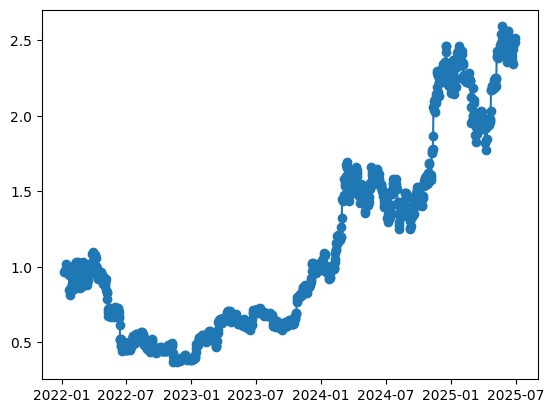

In [37]:
# Plot profit
# plt.plot(dates, np.cumsum(pnls))
# plt.plot(dates, np.cumsum(pnls))
plt.plot(dates,np.cumprod(1+np.array(pnls)),'-o')
#plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
#plt.plot(dates, np.cumsum(pnls))
#plt.plot(unrlzd_dates, np.cumsum(unrlzd))